# NonlinearSolve.jl

Benedict Nguyen

The core purpose of NonlinearSolve.jl is to solve non linear systems of equations.

##### Installation and Setup

In [2]:
using Pkg
using Plots
Pkg.add("NonlinearSolve")

   Resolving package versions...
  No Changes to `~/.julia/environments/v1.10/Project.toml`
  No Changes to `~/.julia/environments/v1.10/Manifest.toml`


## 1.) Who is this for?

#### This library is targeted towards scientists and engineers requiring high-performance tools in order to solve non linear systems of equations requiring large computations.

## 2.) Brief notes on developmental process

NonlinearSolve.jl has a pretty large and active community surrounding it. Over the past year there have been 48 contributors, although this number is slightly lower if we account for duplicate accounts. Additionally, over the past month, the project recieved an average of 4.25 commits a week. Community members and contributors of this project communicate on Zulip.

## 3.) Basics

In [3]:
using NonlinearSolve
parabola(u, p) = u[1]^2 - p
p = 1.0
prob = NonlinearProblem(parabola, .1, p)#The second argument is the initial guess, the third argument is the values of p, which are constants
sol = solve(prob, NewtonRaphson())
println("Solution: x = $(sol.u)")

Solution: x = 1.0


Note that `solve()` only finds one root at a time. If we wanted to find multiple roots, we could iterate through multiple initial guesses, but since we know the roots already, we can just make 2 initial guesses we know will converge to distinct roots and push the solutions to an array.

In [4]:
roots = [sol.u]  #Create an array containing one of the roots

prob2 = NonlinearProblem(parabola, -.1, p)
sol2 = solve(prob2, NewtonRaphson())
push!(roots, sol2.u)

2-element Vector{Float64}:
  1.0
 -1.0

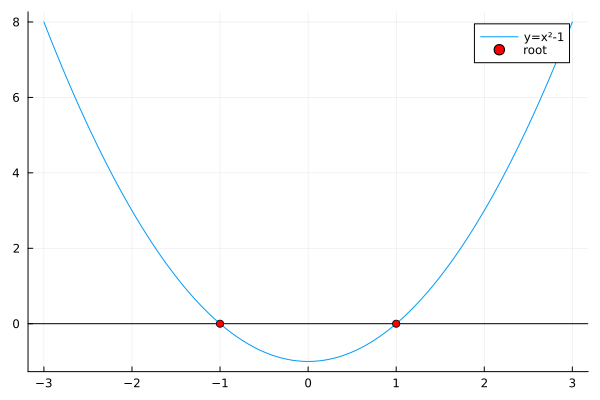

In [5]:
xs = -3:.01:3
plot(xs, [parabola(x, p) for x in xs], label = "y=x²-1", legend = :topright)
hline!([0], color = :black, label = "")
scatter!(roots, [0], color = :red, label = "root")

#### Additional Note

We can use `sol.retcode` to quickly view the behavior of the Newton Method.

For f(x) = x²-1, If our initial guess is x = .1:
Solution Output: 1.0
Return Code Output: Success

For f(x) = x²-1, If our initial guess is x = 0:
Solution Output: 0.0
Return Code Output: Unstable

For f(x) = 4-1/x², If our initial guess is x=10:
Solution Output: 10.0
Return Code Output: Unstable



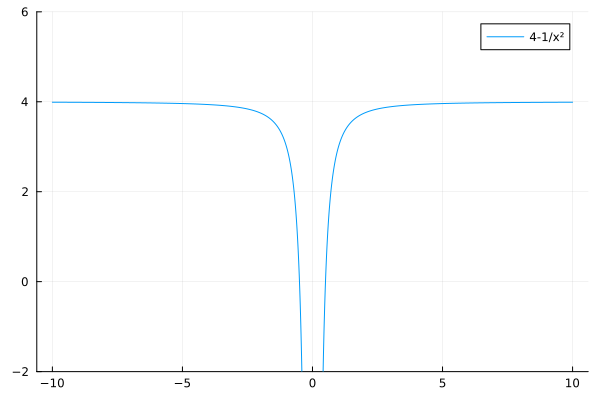

In [6]:
#For f(x) = x²-1, we would expect an initial guess of x = 2 to converge to the root x = 1
prob = NonlinearProblem(parabola, .1, p)
sol = solve(prob, NewtonRaphson())
println("For f(x) = x²-1, If our initial guess is x = .1:\nSolution Output: $(sol.u)\nReturn Code Output: $(sol.retcode)\n")

#For f(x) = x²-1, we would expect an initial guess of x = 0 to diverge since f'(0) = 0
prob = NonlinearProblem(parabola, 0, p)
sol = solve(prob, NewtonRaphson())
println("For f(x) = x²-1, If our initial guess is x = 0:\nSolution Output: $(sol.u)\nReturn Code Output: $(sol.retcode)\n")

#For f(x) = 4-1/x², we would expect a guess of x = 10 to blow up and diverge.
f(u, p) = p - (1/u[1]^2)
p = 4
prob = NonlinearProblem(f, 10, p)
sol = solve(prob, NewtonRaphson())
println("For f(x) = 4-1/x², If our initial guess is x=10:\nSolution Output: $(sol.u)\nReturn Code Output: $(sol.retcode)\n")

xs = -10:.01:10
plot(xs, [f(x, 4) for x in xs], label = "4-1/x²", ylims = (-2, 6))

#### Caution

For f(x) = x^20, If our initial guess is x=.5:
Solution Output: 0.38122726182060657
Return Code Output: Success



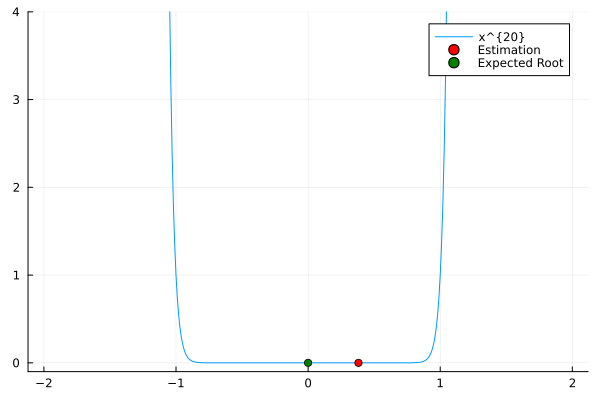

In [7]:
#For f(x) = x^30, we would expect the method to take a long time to get to the root.
f(u, p) = u[1]^30
prob = NonlinearProblem(f, .5, 0)
sol = solve(prob, NewtonRaphson())
println("For f(x) = x^20, If our initial guess is x=.5:\nSolution Output: $(sol.u)\nReturn Code Output: $(sol.retcode)\n")

xs = -2:.01:2
plot(xs, [f(x, 0) for x in xs], label = "x^{20}", ylims = (-.1, 4))
scatter!([sol.u], [f(sol.u, 0)], color=:red, label = "Estimation")
scatter!([0],[0], color=:green, label = "Expected Root")

This happens because the return code is based off the residual which we can use `sol.resid` to obtain. Since we know the true root, lets compare the residual with the error:

In [8]:
println("The Error is: $(sol.u-0)")
println("The Residual is: $(sol.resid)")

The Error is: 0.38122726182060657
The Residual is: 2.7259538129183167e-13


## 4.) Solving Non Linear Systems

#### Our system of equations:

\begin{cases}
  x^2 + y^2 - z &= 0 \\
  x^2 + y^2 +z^2 -4 &= 0 \\
  x + y - z &= 0
\end{cases}

We can set up a system of equations using `f(u,p) = []`

In [9]:
f(u,p) = [u[1]^2 + u[2]^2 - u[3], 
          u[1]^2 + u[2]^2 + u[3]^2 - p,
          u[1] + u[2] - u[3]
]
p=4;

#### Work the problem by hand:

##### This section is just a bunch of algebra to find points of intersection so that we can determine the error and confirm the solve function works, skip over it

\begin{align*}
x^2 + y^2 - z &= 0 \tag{1}\\
x^2 + y^2 +z^2 -4 &= 0 \tag{2}\\
x + y - z &= 0 \tag{3}
\end{align*}

We can rearrange equation $(1)$ so that $x^2 + y^2 = z$ and equation $(2)$ so $x^2 + y^2 = 4-z^2$

\begin{align*}
4 - z^2 &= z \\
z^2 + z - 4 &= 0
\end{align*}

Then we use the quadratic formula to find $z$:

\begin{align*}
z = \frac{-1 \pm \sqrt{17}}{2}
\end{align*}

Since $x^2 + y^2 = z$, we know that our $z$ must be positive.

\begin{align*}
z = \frac{-1 + \sqrt{17}}{2}
\end{align*}

Our intersections lie on the plane $z = \frac{-1 + \sqrt{17}}{2}$, so we can make it easier to visualize by graphing everything onto a the plane $z = \frac{-1 + \sqrt{17}}{2}$ which is parallel to the xy-plane.

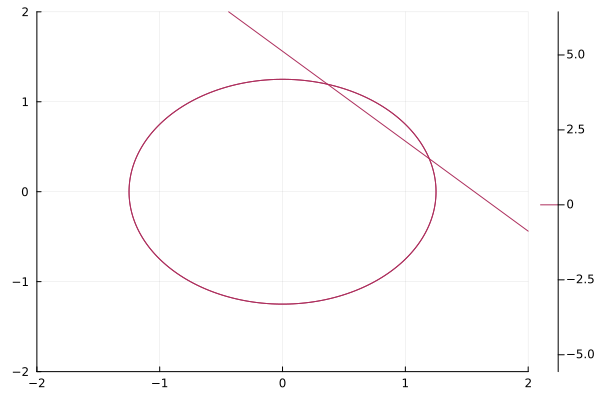

In [10]:
z = .5(-1+sqrt(17))

xs = -2:.01:2
ys = -2:.01:2
contour(xs, ys, (x,y) -> x^2 + y^2 - z, levels=[0])
contour!(xs, ys, (x,y) -> x^2 + y^2 +z^2 - 4, levels=[0])
contour!(xs, ys, (x,y) -> x+y-z, levels=[0])

Now we need to find where $x + y = \frac{-1 + \sqrt{17}}{2}$ and $x^2 + y^2 = \frac{-1 + \sqrt{17}}{2}$ intersect. For simplicity, let $u=\frac{-1 + \sqrt{17}}{2}$

\begin{align*}
x + y &= u \\
y &= u - x 
\end{align*}

Plug into $x^2 + y^2 = \frac{-1 + \sqrt{17}}{2}$:
\begin{align*}
x^2 + (u - x)^2 &= u \\
x^2 + (u^2 - 2ux + x^2) &= u \\
2x^2 - 2ux + u^2 - u &= 0 \\
x^2 - ux + \frac{1}{2}(u^2-u) &= 0
\end{align*}

Quadratic Equation:

\begin{align*}
&\frac{u \pm \sqrt{u^2 - 2(u^2-u)}}{2} \\
\\
\Rightarrow& \frac{u \pm \sqrt{u^2 - 2u^2 + 2u}}{2}
\\
\Rightarrow& \frac{u \pm \sqrt{-u^2 + 2u}}{2}
\end{align*}

x1 = 0.3670559577840663
x2 = 1.1944968550247639

y1 = 1.1944968550247639
y2 = 0.3670559577840664

Point 1: (0.3670559577840663, 1.1944968550247639, 1.5615528128088303)
Point 2: (1.1944968550247639, 0.3670559577840664, 1.5615528128088303)


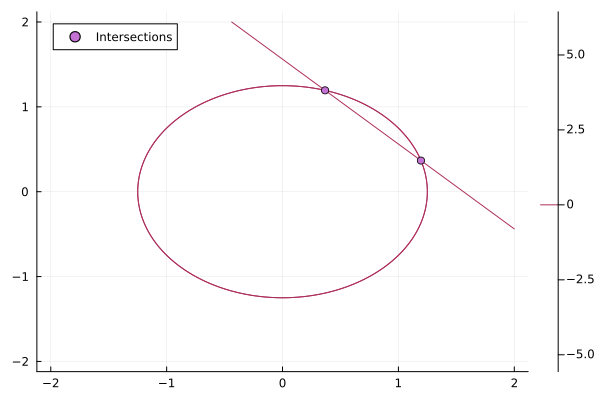

In [11]:
u = z
#x values:
println("x1 = $((u-sqrt(-u^2+2u))/2)"); x1 = (u-sqrt(-u^2+2u))/2
println("x2 = $((u+sqrt(-u^2+2u))/2)"); x2 = (u+sqrt(-u^2+2u))/2
println()

#Plugging in x values:
println("y1 = $(u - x1)"); y1 = u - x1
println("y2 = $(u - x2)"); y2 = u - x2
println()

#Points of intersection:
println("Point 1: ($(x1), $(y1), $(u))");
println("Point 2: ($(x2), $(y2), $(u))");

#Graph:
xs = -2:.01:2
ys = -2:.01:2
contour(xs, ys, (x,y) -> x^2 + y^2 - u, levels=[0])
contour!(xs, ys, (x,y) -> x^2 + y^2 +u^2 - 4, levels=[0])
contour!(xs, ys, (x,y) -> x+y-u, levels=[0])
scatter!([x1, x2],[y1, y2], label="Intersections")

solve() converges on the root at Point 2 with initial guess (1,.3,2): 
[1.194496855024764, 0.3670559577840662, 1.5615528128088303]


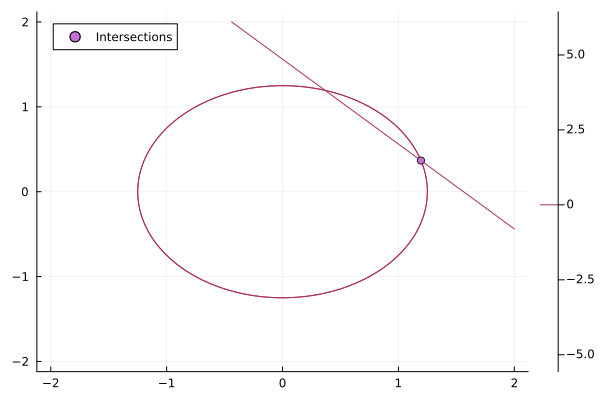

In [12]:
prob = NonlinearProblem(f, [1,.3,2], p)
sol = solve(prob, NewtonRaphson())
println("solve() converges on the root at Point 2 with initial guess (1,.3,2): \n$(sol.u)")
#Graph:
xs = -2:.01:2
ys = -2:.01:2
contour(xs, ys, (x,y) -> x^2 + y^2 - u, levels=[0])
contour!(xs, ys, (x,y) -> x^2 + y^2 +u^2 - 4, levels=[0])
contour!(xs, ys, (x,y) -> x+y-u, levels=[0])
scatter!([sol.u[1]], [sol.u[2]], label="Intersections")

#### Absolute Error

In [13]:
println("The absolute error is: $(sqrt((sol.u[1] - x2)^2 + (sol.u[2] - y2)^2 + (sol.u[3] - u)^2))")

The absolute error is: 3.1401849173675503e-16


## 5.) Question

#### We see that solve() converges to a solution of a system of non linear equations for the guess $(1, .3, 2)$, but for an initial guess like $(1,1,1)$, the Newton Method actually diverges. My questions are: How does NonlinearSolve.jl expand the Newton Method implementation we've learned in this course into higher dimensions, how can we use this information to make better initial guesses, and how does this implementation impact efficiency?

#### Divergence Example:

In [14]:
prob = NonlinearProblem(f, [1,1,1], p)
sol = solve(prob, NewtonRaphson())

┌ Warning: Potential Rank Deficient Matrix Detected. Attempting to solve using Pivoted QR Factorization.
└ @ NonlinearSolveBaseLinearSolveExt ~/.julia/packages/NonlinearSolveBase/5ckRl/ext/NonlinearSolveBaseLinearSolveExt.jl:33
┌ Warning: Potential Rank Deficient Matrix Detected. Attempting to solve using Pivoted QR Factorization.
└ @ NonlinearSolveBaseLinearSolveExt ~/.julia/packages/NonlinearSolveBase/5ckRl/ext/NonlinearSolveBaseLinearSolveExt.jl:33
┌ Warning: Potential Rank Deficient Matrix Detected. Attempting to solve using Pivoted QR Factorization.
└ @ NonlinearSolveBaseLinearSolveExt ~/.julia/packages/NonlinearSolveBase/5ckRl/ext/NonlinearSolveBaseLinearSolveExt.jl:33


retcode: MaxIters
u: 3-element Vector{Float64}:
 0.8639620834660161
 0.8639620834660161
 1.5878655764190335

## 6.) Proposed Experiment

#### As a group project, we could compare the iterations and time per iteration between the class iteration and NonlinearSolve. It might also be interesting to see if either implementations is more or less prone to divergence than the other.